# Lekce 08 - Soubory a grafy

Obsah:

* proč soubory
* textový soubor: čtení a zápis
* cesty a složky: `pathlib`
* čtení CSV modulem `csv`
* zápis CSV
* JSON
* grafy: Matplotlib
* uložení grafu do souboru
* časté chyby

Celou lekci provází jeden příklad: zatěžovací zkouška stropní desky.
Naměřená data přijdou v souboru CSV, zadání zkoušky v souboru JSON. Výsledkem
bude vyhodnocená tabulka v CSV, souhrn v JSON a graf v PNG.

Na konec, mimo látku: totéž s balíčkem pandas.

## 1. Proč soubory

Všechno, co program zatím spočítal, zmizelo s restartem kernelu. Soubory
řeší dvě věci:

* **výstup přežije program** - výsledky, tabulky a grafy zůstanou na disku
* **vstup přijde odjinud** - z Excelu, z měřicí ústředny, z exportu BIM
  modelu, od kolegy

Ve stavební praxi jsou nejčastější tři druhy souborů:

| Formát | Co v něm je | Kdo ho vyrábí |
|---|---|---|
| `.txt` | prostý text | kdokoli |
| `.csv` | tabulka jako text, hodnoty oddělené čárkou nebo středníkem | Excel, měřicí přístroje, databáze |
| `.json` | strukturovaná data: slovníky a seznamy | webové služby, konfigurace programů |

Všechny tři jsou **textové**: otevřete je v Poznámkovém bloku nebo ve VS Code
a přečtete je.

## 2. Textový soubor: čtení a zápis

Soubor se otevírá funkcí `open(cesta, rezim, encoding="utf-8")`. Blok `with`
soubor na konci sám zavře, i když uvnitř nastane chyba.

**Zápis.** Režim `"w"` (write) soubor vytvoří, a pokud už existuje,
**přepíše ho**. `write` nepřidává konec řádku, `"\n"` se píše ručně:

In [1]:
with open("poznamky.txt", "w", encoding="utf-8") as f:
    f.write("Zatěžovací zkouška stropu 2.NP\n")
    f.write("Snímače průhybu: L, S, P\n")

**Čtení.** Bez režimu se soubor otevře pro čtení. `read()` vrátí celý obsah
jako jeden řetězec:

In [2]:
with open("poznamky.txt", encoding="utf-8") as f:
    obsah = f.read()

print(obsah)
print(type(obsah), len(obsah))

Zatěžovací zkouška stropu 2.NP
Snímače průhybu: L, S, P

<class 'str'> 56


Soubor jde také procházet cyklem **po řádcích**. Každý řádek končí `"\n"`,
proto `strip()`:

In [3]:
with open("poznamky.txt", encoding="utf-8") as f:
    for cislo, radek in enumerate(f, start=1):
        print(cislo, radek.strip())

1 Zatěžovací zkouška stropu 2.NP
2 Snímače průhybu: L, S, P


**Připsání.** Režim `"a"` (append) přidá text na konec a nic nepřepíše.
Hodí se na deník nebo záznam průběhu výpočtu:

In [4]:
with open("poznamky.txt", "a", encoding="utf-8") as f:
    f.write("Zkouška proběhla 12. 11. 2026\n")

with open("poznamky.txt", encoding="utf-8") as f:
    print(f.read())

Zatěžovací zkouška stropu 2.NP
Snímače průhybu: L, S, P
Zkouška proběhla 12. 11. 2026



| Režim | Co dělá | Když soubor neexistuje |
|---|---|---|
| `"r"` (výchozí) | čtení | chyba `FileNotFoundError` |
| `"w"` | zápis, **smaže původní obsah** | vytvoří ho |
| `"a"` | zápis na konec | vytvoří ho |

**`encoding="utf-8"`** píšeme vždycky. Bez něj Windows použije starší české
kódování a diakritika se rozsype (viz Časté chyby).

## 3. Cesty a složky: `pathlib`

Relativní cesta jako `"poznamky.txt"` nebo `"Data/zkouska.json"` se počítá od
složky, ve které je notebook (u skriptu od složky, ze které ho spouštíte).
Lomítko `/` funguje ve Windows i jinde.

Modul `pathlib` ze standardní knihovny pracuje s cestami jako s objekty:

In [5]:
from pathlib import Path

data = Path("Data")
print(data.exists())

for soubor in data.glob("*.csv"):        # vsechny soubory s priponou .csv
    print(soubor.name)

True
rozpocet.csv
zatezovaci_zkouska.csv
zatezovaci_zkouska_excel.csv


Výstupy budeme ukládat do samostatné složky, aby se nemíchaly se vstupy.
`exist_ok=True` znamená "když už složka je, nevadí":

In [6]:
vystupy = Path("vystupy")
vystupy.mkdir(exist_ok=True)

print(vystupy / "graf.png")      # cesty se skladaji lomitkem

vystupy\graf.png


## 4. Čtení CSV modulem `csv`

CSV je obyčejný text. Podívejme se na začátek souboru s měřením:

In [7]:
with open("Data/zatezovaci_zkouska.csv", encoding="utf-8") as f:
    for i in range(4):
        print(f.readline().strip())

krok,zatizeni_kN,pruhyb_L_mm,pruhyb_S_mm,pruhyb_P_mm
0,0,0.00,0.00,0.00
1,10,0.12,2.31,0.10
2,20,0.25,4.70,0.21


První řádek jsou názvy sloupců, další řádky jsou kroky zkoušky: zatížení
v kN a průhyby ze tří snímačů v mm. Strop se zatížil po 10 kN až na 50 kN
a pak zase odtížil.

Řádek by šel rozdělit metodou `split(",")`. Modul `csv` ale zvládne i hodnoty
s čárkou uvnitř uvozovek a další zvláštnosti, proto ho používejte. CSV se
otevírá s `newline=""`, tak to modul `csv` vyžaduje.

**`csv.reader`** vrací každý řádek jako seznam řetězců:

In [8]:
import csv

with open("Data/zatezovaci_zkouska.csv", encoding="utf-8", newline="") as f:
    radky = list(csv.reader(f))

print(radky[0])
print(radky[1])
print(type(radky[1][1]))      # i cisla jsou text

['krok', 'zatizeni_kN', 'pruhyb_L_mm', 'pruhyb_S_mm', 'pruhyb_P_mm']
['0', '0', '0.00', '0.00', '0.00']
<class 'str'>


**Všechno je text.** Čísla je potřeba převést funkcí `float()` nebo `int()`.

Pohodlnější je **`csv.DictReader`**: první řádek použije jako klíče a každý
další řádek vrátí jako slovník. Na sloupce se pak odkazujeme jménem, ne
číslem:

In [9]:
zatizeni = []
pruhyb_L = []
pruhyb_S = []
pruhyb_P = []

with open("Data/zatezovaci_zkouska.csv", encoding="utf-8", newline="") as f:
    for radek in csv.DictReader(f):
        zatizeni.append(float(radek["zatizeni_kN"]))
        pruhyb_L.append(float(radek["pruhyb_L_mm"]))
        pruhyb_S.append(float(radek["pruhyb_S_mm"]))
        pruhyb_P.append(float(radek["pruhyb_P_mm"]))

print(radek)          # posledni radek jako slovnik
print(zatizeni)
print(pruhyb_S)

{'krok': '10', 'zatizeni_kN': '0', 'pruhyb_L_mm': '0.15', 'pruhyb_S_mm': '1.21', 'pruhyb_P_mm': '0.12'}
[0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 40.0, 30.0, 20.0, 10.0, 0.0]
[0.0, 2.31, 4.7, 7.18, 9.81, 12.62, 10.95, 8.71, 6.32, 3.85, 1.21]


**Poznámka: CSV z českého Excelu.** Český Excel ukládá CSV jinak: desetinná
čárka je zabraná, a tak odděluje hodnoty **středníkem** a čísla píše
s desetinnou čárkou (`0,63`). Když na takový soubor narazíte, stačí dvě věci:
`csv.reader(f, delimiter=";")` a před převodem na číslo
`float(text.replace(",", "."))`. Dál se tím zabývat nebudeme, všechny soubory
v kurzu jsou v obvyklém tvaru s čárkou a desetinnou tečkou.

## 5. Zápis CSV

Snímače u podpor ukazují, že i podpory se trochu stlačily. Skutečný průhyb
desky je proto průhyb uprostřed minus průměrné sednutí podpor:

`korigovany = S - (L + P) / 2`

In [10]:
korigovany = [s - (l + p) / 2 for l, s, p in zip(pruhyb_L, pruhyb_S, pruhyb_P)]
print([round(k, 3) for k in korigovany])

[0.0, 2.2, 4.47, 6.83, 9.34, 12.025, 10.435, 8.28, 5.985, 3.61, 1.075]


**`csv.writer`** zapisuje řádky ze seznamů. Opět `newline=""`, jinak by ve
Windows vznikl za každým řádkem prázdný řádek:

In [11]:
with open("vystupy/vyhodnoceni.csv", "w", encoding="utf-8", newline="") as f:
    zapis = csv.writer(f)
    zapis.writerow(["zatizeni_kN", "pruhyb_S_mm", "korigovany_mm"])
    for F, s, k in zip(zatizeni, pruhyb_S, korigovany):
        zapis.writerow([F, s, round(k, 3)])

with open("vystupy/vyhodnoceni.csv", encoding="utf-8") as f:
    print(f.read())

zatizeni_kN,pruhyb_S_mm,korigovany_mm
0.0,0.0,0.0
10.0,2.31,2.2
20.0,4.7,4.47
30.0,7.18,6.83
40.0,9.81,9.34
50.0,12.62,12.025
40.0,10.95,10.435
30.0,8.71,8.28
20.0,6.32,5.985
10.0,3.85,3.61
0.0,1.21,1.075



## 6. JSON

CSV je jedna tabulka. Data se strukturou, třeba parametry zkoušky
s vnořeným popisem snímačů, se ukládají do **JSON**. Soubor `Data/zkouska.json`:

```json
{
  "nazev": "Zatěžovací zkouška stropu 2.NP",
  "datum": "2026-11-12",
  "rozpeti_m": 6.0,
  "pomer_limitu": 250,
  "max_podil_trvaleho": 0.2,
  "snimace": {
    "L": "u levé podpory",
    "S": "uprostřed rozpětí",
    "P": "u pravé podpory"
  }
}
```

Vypadá jako slovník v Pythonu a skoro jím je. `json.load` z něj slovník
opravdu udělá:

In [12]:
import json

with open("Data/zkouska.json", encoding="utf-8") as f:
    zadani = json.load(f)

print(type(zadani))
print(zadani["nazev"], zadani["rozpeti_m"])
print(zadani["snimace"]["S"])

<class 'dict'>
Zatěžovací zkouška stropu 2.NP 6.0
uprostřed rozpětí


| JSON | Python |
|---|---|
| objekt `{...}` | `dict` |
| pole `[...]` | `list` |
| text `"..."` | `str` |
| číslo `6.0`, `250` | `float`, `int` |
| `true`, `false` | `True`, `False` |
| `null` | `None` |

Klíče v JSON jsou vždy text. Komentáře JSON nepovoluje.

Teď zkoušku vyhodnotíme. Průhyb nesmí překročit `L / 250` a trvalý průhyb
po odtížení nesmí být víc než 20 % největšího průhybu. Obě hodnoty bereme ze
zadání, ne natvrdo z kódu:

In [13]:
limit_mm = zadani["rozpeti_m"] * 1000 / zadani["pomer_limitu"]
max_pruhyb = max(korigovany)
trvaly = korigovany[-1]
podil_trvaleho = trvaly / max_pruhyb

vysledek = {
    "nazev": zadani["nazev"],
    "max_pruhyb_mm": round(max_pruhyb, 2),
    "limit_mm": limit_mm,
    "trvaly_pruhyb_mm": round(trvaly, 2),
    "podil_trvaleho": round(podil_trvaleho, 3),
    "vyhovuje": max_pruhyb <= limit_mm and podil_trvaleho <= zadani["max_podil_trvaleho"],
}
print(vysledek)

{'nazev': 'Zatěžovací zkouška stropu 2.NP', 'max_pruhyb_mm': 12.02, 'limit_mm': 24.0, 'trvaly_pruhyb_mm': 1.07, 'podil_trvaleho': 0.089, 'vyhovuje': True}


`json.dump` zapíše slovník do souboru. `indent=2` ho odsadí, aby byl čitelný,
a `ensure_ascii=False` nechá diakritiku jako diakritiku:

In [14]:
with open("vystupy/vysledek.json", "w", encoding="utf-8") as f:
    json.dump(vysledek, f, indent=2, ensure_ascii=False)

print(Path("vystupy/vysledek.json").read_text(encoding="utf-8"))

{
  "nazev": "Zatěžovací zkouška stropu 2.NP",
  "max_pruhyb_mm": 12.02,
  "limit_mm": 24.0,
  "trvaly_pruhyb_mm": 1.07,
  "podil_trvaleho": 0.089,
  "vyhovuje": true
}


`Path.read_text()` je zkratka: otevře soubor, přečte ho a zavře v jednom
volání. Podobně `Path.write_text(text)`.

## 7. Grafy: Matplotlib

Čísla ve slovníku nikdo neocení, graf ano. **Matplotlib** je nejrozšířenější
balíček na grafy v Pythonu. Instalace a obvyklý import:

```
uv add matplotlib
```

In [15]:
import matplotlib.pyplot as plt

Funkce `plt.plot(x, y)` dostane dva stejně dlouhé seznamy a body spojí čarou.
Každé další volání přidá do grafu další řadu:

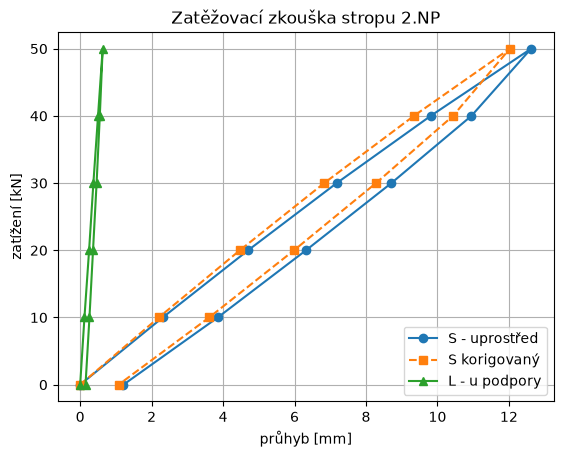

In [16]:
plt.plot(pruhyb_S, zatizeni, marker="o", label="S - uprostřed")
plt.plot(korigovany, zatizeni, marker="s", linestyle="--", label="S korigovaný")
plt.plot(pruhyb_L, zatizeni, marker="^", label="L - u podpory")
plt.xlabel("průhyb [mm]")
plt.ylabel("zatížení [kN]")
plt.title("Zatěžovací zkouška stropu 2.NP")
plt.legend()
plt.grid(True)
plt.show()

Zatěžovací a odtěžovací větev se nepřekrývají. Po odtížení zůstal malý
trvalý průhyb.

* `label` je text do legendy, legendu zobrazí `plt.legend()`
* `plt.show()` graf zobrazí; v notebooku se ukáže i bez něj, ve skriptu
  spuštěném přes `uv run` je nutné

| Argument | Příklady hodnot |
|---|---|
| `color` | `"red"`, `"black"`, `"gray"`, `"tab:blue"` |
| `linestyle` | `"-"`, `"--"`, `":"`, `""` (bez čáry) |
| `marker` | `"o"`, `"s"`, `"x"`, `"^"` |
| `linewidth` | `0.5`, `2` |
| `label` | text do legendy |

**Víc grafů v jednom obrázku.** `plt.subplots()` vrátí **obrázek** `fig`
a **osy** `ax`. Kreslí se metodami os, popisky mají předponu `set_`:

| `plt` | osy `ax` |
|---|---|
| `plt.plot(x, y)` | `ax.plot(x, y)` |
| `plt.xlabel("...")` | `ax.set_xlabel("...")` |
| `plt.title("...")` | `ax.set_title("...")` |

Vlevo pracovní diagram, vpravo sloupcový graf (`bar`) s největším průhybem
na snímačích a vodorovná čára limitu (`axhline`):

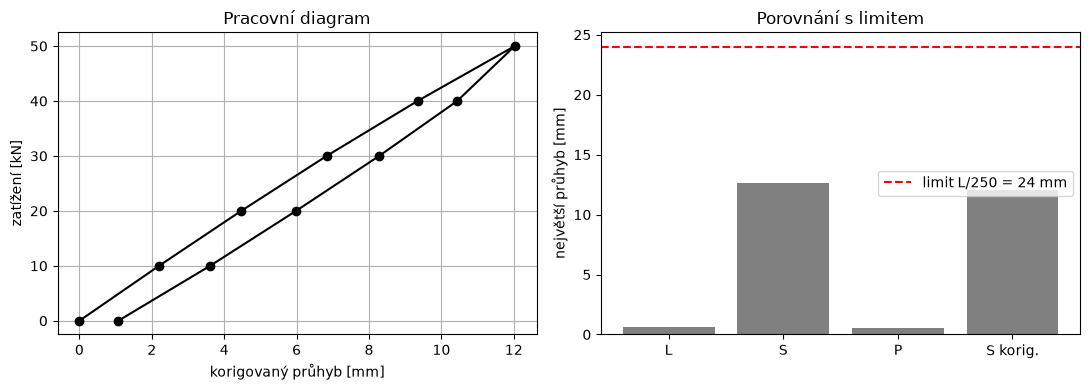

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(korigovany, zatizeni, marker="o", color="black")
ax1.set_xlabel("korigovaný průhyb [mm]")
ax1.set_ylabel("zatížení [kN]")
ax1.set_title("Pracovní diagram")
ax1.grid(True)

snimace = ["L", "S", "P", "S korig."]
maxima = [max(pruhyb_L), max(pruhyb_S), max(pruhyb_P), max(korigovany)]
ax2.bar(snimace, maxima, color="gray")
ax2.axhline(limit_mm, color="red", linestyle="--", label=f"limit L/250 = {limit_mm:.0f} mm")
ax2.set_ylabel("největší průhyb [mm]")
ax2.set_title("Porovnání s limitem")
ax2.legend(loc="center right")

fig.tight_layout()       # at se popisky neprekryvaji
plt.show()

## 8. Uložení grafu do souboru

Graf do zprávy nebo do protokolu se uloží metodou `fig.savefig`. Formát se
pozná podle přípony: `.png` pro obrázek, `.pdf` nebo `.svg` pro vektorový
výkres, který jde libovolně zvětšit. `dpi` určí rozlišení PNG.

`savefig` volejte **před** `plt.show()`. Ve skriptu `show` obrázek po zavření
okna zahodí a uložil by se prázdný.

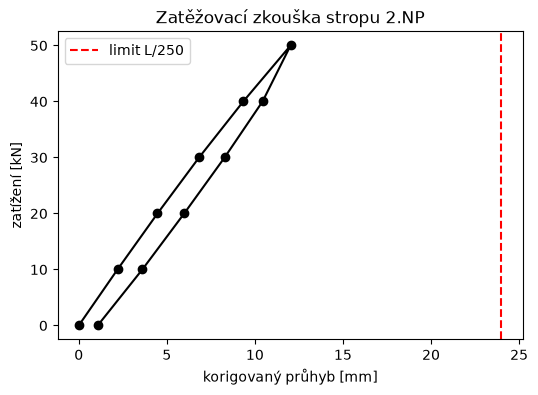

pandas_excel.csv
vyhodnoceni.csv
vyhodnoceni_excel.csv
vysledek.json
zkouska.pdf
zkouska.png


In [18]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(korigovany, zatizeni, marker="o", color="black")
ax.axvline(limit_mm, color="red", linestyle="--", label="limit L/250")
ax.set_xlabel("korigovaný průhyb [mm]")
ax.set_ylabel("zatížení [kN]")
ax.set_title(zadani["nazev"])
ax.legend()

fig.savefig("vystupy/zkouska.png", dpi=200)
fig.savefig("vystupy/zkouska.pdf")
plt.show()

for soubor in Path("vystupy").iterdir():
    print(soubor.name)

Ze vstupů `zatezovaci_zkouska.csv` a `zkouska.json` vznikla vyhodnocená
tabulka v CSV, souhrn v JSON a graf v PNG a PDF. Přijde-li zítra další
zkouška, stačí změnit cestu k souboru a spustit notebook znovu.

## 9. Časté chyby

**Soubor nenalezen.** Cesta se počítá od složky s notebookem. Tady chybí
`Data/`:

In [19]:
open("zkouska.json", encoding="utf-8")

FileNotFoundError: [Errno 2] No such file or directory: 'zkouska.json'

**Špatné kódování.** Soubor uložený v UTF-8 a přečtený jako `cp1250` (nebo
naopak) má rozsypanou diakritiku:

In [20]:
with open("poznamky.txt", encoding="cp1250") as f:
    print(f.read())

ZatÄ›ĹľovacĂ­ zkouĹˇka stropu 2.NP
SnĂ­maÄŤe prĹŻhybu: L, S, P
ZkouĹˇka probÄ›hla 12. 11. 2026



**Čísla z CSV jsou text.** Sčítání textu je spojování:

In [21]:
print(radky[2][1] + radky[3][1])
print(float(radky[2][1]) + float(radky[3][1]))

1020
30.0


**Režim `"w"` přepíše soubor.** Bez varování. Když chcete přidávat, použijte
`"a"`. Vstupní data a výstupy držte v různých složkách.

**Chybí `newline=""`.** CSV zapsané ve Windows bez něj má za každým řádkem
prázdný řádek.

**`savefig` až po `plt.show()`.** Uloží se prázdný obrázek.

**JSON s jednoduchými uvozovkami nebo s čárkou za posledním prvkem.**
`{'a': 1,}` je platný Python, ale neplatný JSON. `json.load` skončí chybou
`JSONDecodeError`.

## Shrnutí

| Zápis | Význam |
|---|---|
| `with open(cesta, "r", encoding="utf-8") as f:` | otevření souboru, na konci se sám zavře |
| `f.read()`, `for radek in f:` | celý obsah, po řádcích |
| `f.write(text)` | zápis, `"\n"` ručně |
| `"r"`, `"w"`, `"a"` | čtení, přepsání, připsání |
| `Path("Data").glob("*.csv")` | soubory podle masky |
| `Path("vystupy").mkdir(exist_ok=True)` | vytvoření složky |
| `Path(...).read_text(encoding="utf-8")` | přečtení souboru jedním voláním |
| `csv.reader(f)`, `csv.DictReader(f)` | řádky jako seznamy, jako slovníky |
| `csv.writer(f).writerow([...])` | zápis řádku ze seznamu |
| `newline=""` | povinné při čtení i zápisu CSV |
| `json.load(f)`, `json.dump(data, f, indent=2, ensure_ascii=False)` | čtení, zápis JSON |
| `plt.plot(x, y, label=...)` | čárový graf |
| `fig, ax = plt.subplots()` | obrázek a osy |
| `ax.bar`, `ax.axhline`, `ax.axvline` | sloupce, vodorovná a svislá čára |
| `ax.set_xlabel`, `ax.set_title`, `ax.legend()` | popisky a legenda |
| `fig.savefig("graf.png", dpi=200)` | uložení grafu |

Co si odnést:

* soubor otevírat přes `with` a vždycky s `encoding="utf-8"`
* CSV a JSON jsou text; čísla z CSV je potřeba převést
* JSON = slovníky a seznamy; hodí se na zadání a souhrny výsledků
* parametry výpočtu patří do vstupního souboru, ne natvrdo do kódu
* graf: data, popisky, legenda, `savefig`, `show`

**Kam dál.** Tím kurz končí. Pro práci s velkými tabulkami a rychlé výpočty
s čísly navazují balíčky **NumPy** (pole a výpočty bez cyklu) a **pandas**
(tabulky). Ukázka níže ukazuje, kolik práce pandas ušetří.

## Ukázka: co Python ještě umí

*Tahle část není látka do testu. Nemusíte rozumět každému řádku.*

Balíček `pandas` pracuje s tabulkami jako Excel v Pythonu. Načtení CSV,
výpočet korigovaného průhybu, graf a zápis zpět do CSV zvládne
na pár řádcích. Instalace: `uv add pandas`.

    krok  zatizeni_kN  pruhyb_L_mm  pruhyb_S_mm  pruhyb_P_mm  korigovany_mm
0      0            0         0.00         0.00         0.00          0.000
1      1           10         0.12         2.31         0.10          2.200
2      2           20         0.25         4.70         0.21          4.470
3      3           30         0.37         7.18         0.33          6.830
4      4           40         0.50         9.81         0.44          9.340
5      5           50         0.63        12.62         0.56         12.025
6      6           40         0.55        10.95         0.48         10.435
7      7           30         0.46         8.71         0.40          8.280
8      8           20         0.36         6.32         0.31          5.985
9      9           10         0.26         3.85         0.22          3.610
10    10            0         0.15         1.21         0.12          1.075
nejvetsi korigovany pruhyb: 12.02 mm


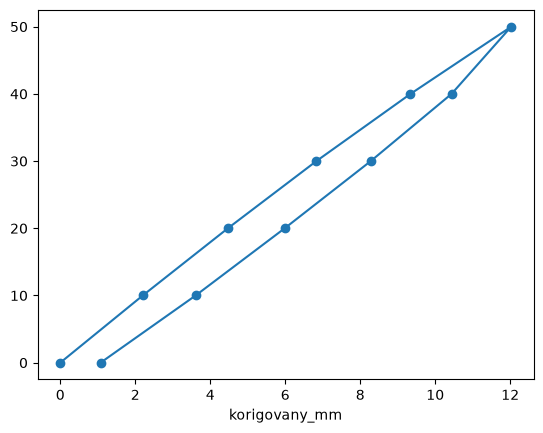

In [22]:
import pandas as pd

tab = pd.read_csv("Data/zatezovaci_zkouska.csv")
tab["korigovany_mm"] = tab["pruhyb_S_mm"] - (tab["pruhyb_L_mm"] + tab["pruhyb_P_mm"]) / 2

print(tab)
print("nejvetsi korigovany pruhyb:", tab["korigovany_mm"].max().round(2), "mm")

tab.plot(x="korigovany_mm", y="zatizeni_kN", marker="o", legend=False)
plt.show()

tab.to_csv("vystupy/pandas_vyhodnoceni.csv", index=False)

Celý oddíl 4 a 5 se smrskl na tři řádky. Výpočet běží na celém sloupci
najednou, bez cyklu. Pandas zvládne i statisíce řádků, soubory Excelu
`.xlsx` (s balíčkem `openpyxl`) nebo seskupování dat podle hodnot ve sloupci.